# Credit Card Fraud Detection using Machine Learning

## 1. Project Overview

### Problem Statement
The objective of this project is to build machine learning models that can automatically identify fraudulent credit card transactions using transaction details, customer demographics and merchant information. Fraud detection is a challenging classification problem because fraudulent transactions are extremely rare compared with genuine ones, so a model must be able to find a very small number of fraud cases among millions of legitimate transactions.

### Dataset Description
The project uses a publicly available simulated credit card transaction dataset, supplied as separate training and testing files, covering transactions from **January 2019 to December 2020**.

- **Size:** 1,852,394 transactions after combining both files, described by 22 original features.
- **Customers:** 999 unique credit cards.
- **Information available:** transaction date and time, transaction amount, merchant and merchant category, customer demographics (gender, age, job), customer and merchant locations.
- **Target variable:** `is_fraud` (0 = genuine transaction, 1 = fraudulent transaction).
- **Class imbalance:** only **9,651 transactions (about 0.52%)** are fraudulent.

### Objectives
- Understand the structure and quality of the dataset.
- Explore patterns related to fraudulent transactions, such as transaction amount, merchant category and time of day.
- Engineer meaningful features, such as customer age, distance between the customer and the merchant, and time-based features.
- Prepare the data for machine learning without introducing data leakage.
- Build and compare three classification models: **Logistic Regression, Random Forest and XGBoost**.
- Address the severe class imbalance using **SMOTE** and **class weights**.
- Optimize the decision threshold to balance fraud detection against false alarms.
- Evaluate the models using metrics suitable for imbalanced data: **Precision, Recall, F1-Score, ROC-AUC and PR-AUC**.
- Identify the features that contribute most to fraud prediction.

### Approach
1. Exploratory data analysis and feature engineering.
2. A **chronological train-test split**: the models are trained on earlier transactions (before 21 June 2020) and tested on later ones, which mirrors real-world deployment where a model must detect fraud in future transactions.
3. Target encoding of high-cardinality variables, using the training data only to prevent target leakage.
4. Model building, hyperparameter tuning and imbalance handling.
5. Model evaluation and comparison.

### Why Accuracy Is Not Used as the Main Metric
Because only about 0.5% of transactions are fraudulent, a model that labels every transaction as genuine would still reach high accuracy while detecting no fraud at all. Therefore, this project focuses on Precision, Recall, F1-Score and PR-AUC, which measure how well the models actually detect fraud.

## 2. Importing Required Libraries

This section imports the Python libraries used for data manipulation, visualization and machine learning. **pandas** and **NumPy** handle the data and numerical calculations, while **Matplotlib** and **Seaborn** are used to create the charts for exploratory analysis. A clean plot style is applied so that all visualizations are easy to read.

Libraries needed for specific tasks, such as scikit-learn for model building and evaluation, XGBoost for gradient boosting, and imbalanced-learn for SMOTE, are imported later in the sections where they are first used.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display plots inside the notebook
%matplotlib inline

# Improve plot style
sns.set_style("whitegrid")

## 3. Loading the Dataset

The dataset was provided as two separate files: a **training file** and a **testing file**. Both files were loaded into pandas DataFrames and **merged into a single dataset**, so that exploratory data analysis and feature engineering can be carried out on the complete set of transactions.

The merged data is then split again later in the project, in the Train-Test Split section. This is done chronologically (by transaction date), so the final training and testing sets are built deliberately instead of relying on the original file divisissful.

In [5]:
df_1 = pd.read_csv("C:\\Users\\ishik\\Downloads\\fraudTrain.csv.zip")
df_2 = pd.read_csv("C:\\Users\\ishik\\Downloads\\fraudTest.csv.zip")

# Merge train df_1 and df_2
df = pd.concat([df_1, df_2], ignore_index=True)

df = df.drop(columns=["Unnamed: 0"], errors="ignore")

# Convert the transaction time to datetime and sort chronologically
df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])
df = df.sort_values("trans_date_trans_time").reset_index(drop=True)

# Verify the merge
print("Train rows:", len(df_1), "| Test rows:", len(df_2))
print("Combined shape:", df.shape)
print("Rows add up correctly:", len(df) == len(df_1) + len(df_2))
print("Date range:", df["trans_date_trans_time"].min(), "->", df["trans_date_trans_time"].max())

Train rows: 1296675 | Test rows: 555719
Combined shape: (1852394, 22)
Rows add up correctly: True
Date range: 2019-01-01 00:00:18 -> 2020-12-31 23:59:34


## 4. Understanding the Dataset

This section explores the basic structure of the merged dataset by examining its first records, data types and summary statistics. Understanding the data at this stage helps identify quality issues, incorrect data types and unnecessary columns before detailed analysis begins.

In [7]:
df.head(10)

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0
5,2019-01-01 00:04:08,4767265376804500,"fraud_Stroman, Hudson and Erdman",gas_transport,94.63,Jennifer,Conner,F,4655 David Island,Dublin,...,40.3750,-75.2045,2158,Transport planner,1961-06-19,189a841a0a8ba03058526bcfe566aab5,1325376248,40.653382,-76.152667,0
6,2019-01-01 00:04:42,30074693890476,fraud_Rowe-Vandervort,grocery_net,44.54,Kelsey,Richards,F,889 Sarah Station Suite 624,Holcomb,...,37.9931,-100.9893,2691,Arboriculturist,1993-08-16,83ec1cc84142af6e2acf10c44949e720,1325376282,37.162705,-100.153370,0
7,2019-01-01 00:05:08,6011360759745864,fraud_Corwin-Collins,gas_transport,71.65,Steven,Williams,M,231 Flores Pass Suite 720,Edinburg,...,38.8432,-78.6003,6018,"Designer, multimedia",1947-08-21,6d294ed2cc447d2c71c7171a3d54967c,1325376308,38.948089,-78.540296,0
8,2019-01-01 00:05:18,4922710831011201,fraud_Herzog Ltd,misc_pos,4.27,Heather,Chase,F,6888 Hicks Stream Suite 954,Manor,...,40.3359,-79.6607,1472,Public affairs consultant,1941-03-07,fc28024ce480f8ef21a32d64c93a29f5,1325376318,40.351813,-79.958146,0
9,2019-01-01 00:06:01,2720830304681674,"fraud_Schoen, Kuphal and Nitzsche",grocery_pos,198.39,Melissa,Aguilar,F,21326 Taylor Squares Suite 708,Clarksville,...,36.5220,-87.3490,151785,Pathologist,1974-03-28,3b9014ea8fb80bd65de0b1463b00b00e,1325376361,37.179198,-87.485381,0


In [8]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1852394 entries, 0 to 1852393
Data columns (total 22 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   trans_date_trans_time  datetime64[ns]
 1   cc_num                 int64         
 2   merchant               object        
 3   category               object        
 4   amt                    float64       
 5   first                  object        
 6   last                   object        
 7   gender                 object        
 8   street                 object        
 9   city                   object        
 10  state                  object        
 11  zip                    int64         
 12  lat                    float64       
 13  long                   float64       
 14  city_pop               int64         
 15  job                    object        
 16  dob                    object        
 17  trans_num              object        
 18  unix_time             

The `dob` (date of birth) column is stored as text, so it is converted to a datetime format. This allows us to calculate the customer's age later during feature engineering. The `unix_time` column is not converted because it only repeats the transaction time already available in `trans_date_trans_time`; it will be dropped during feature selection.

In [10]:
df["dob"] = pd.to_datetime(df["dob"])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1852394 entries, 0 to 1852393
Data columns (total 22 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   trans_date_trans_time  datetime64[ns]
 1   cc_num                 int64         
 2   merchant               object        
 3   category               object        
 4   amt                    float64       
 5   first                  object        
 6   last                   object        
 7   gender                 object        
 8   street                 object        
 9   city                   object        
 10  state                  object        
 11  zip                    int64         
 12  lat                    float64       
 13  long                   float64       
 14  city_pop               int64         
 15  job                    object        
 16  dob                    datetime64[ns]
 17  trans_num              object        
 18  unix_time             

In [11]:
df.describe()

,trans_date_trans_time,cc_num,amt,zip,lat,long,city_pop,dob,unix_time,merch_lat,merch_long,is_fraud
count,1852394,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06,1852394,1.852394e+06,1.852394e+06,1.852394e+06,1.852394e+06
mean,2020-01-20 21:31:46.801827328,4.173860e+17,7.006357e+01,4.881326e+04,3.853931e+01,-9.022783e+01,8.864367e+04,1973-10-15 11:05:05.744458256,1.358674e+09,3.853898e+01,-9.022794e+01,5.210015e-03
min,2019-01-01 00:00:18,6.041621e+10,1.000000e+00,1.257000e+03,2.002710e+01,-1.656723e+02,2.300000e+01,1924-10-30 00:00:00,1.325376e+09,1.902742e+01,-1.666716e+02,0.000000e+00
25%,2019-07-23 04:13:43.750000128,1.800429e+14,9.640000e+00,2.623700e+04,3.466890e+01,-9.679800e+01,7.410000e+02,1962-08-13 00:00:00,1.343017e+09,3.474012e+01,-9.689944e+01,0.000000e+00
50%,2020-01-02 01:15:31,3.521417e+15,4.745000e+01,4.817400e+04,3.935430e+01,-8.747690e+01,2.443000e+03,1975-11-30 00:00:00,1.357089e+09,3.936890e+01,-8.744069e+01,0.000000e+00
75%,2020-07-23 12:11:25.249999872,4.642255e+15,8.310000e+01,7.204200e+04,4.194040e+01,-8.015800e+01,2.032800e+04,1987-04-23 00:00:00,1.374581e+09,4.195626e+01,-8.024511e+01,0.000000e+00
max,2020-12-31 23:59:34,4.992346e+18,2.894890e+04,9.992100e+04,6.669330e+01,-6.795030e+01,2.906700e+06,2005-01-29 00:00:00,1.388534e+09,6.751027e+01,-6.695090e+01,1.000000e+00
std,NaN,1.309115e+18,1.592540e+02,2.688185e+04,5.071470e+00,1.374789e+01,3.014876e+05,NaN,1.819508e+07,5.105604e+00,1.375969e+01,7.199217e-02


### Interpretation

The first records show that each row represents a single credit card transaction, described by the transaction time, card number, merchant, merchant category, amount, customer details (name, gender, address, job, date of birth), the customer's and the merchant's coordinates, and the target variable `is_fraud`.

The dataset contains **1,852,394 transactions and 22 columns**, made up of **numerical** (`amt`, `lat`, `long`, `city_pop`, `merch_lat`, `merch_long`), **categorical** (`merchant`, `category`, `gender`, `state`, `city`, `job`) and **identifier** variables (`cc_num`, `trans_num`, names and street address). Two columns need attention:

- **`dob`** is stored as text, although it represents a date. It is converted to a datetime format so that the customer's age can be calculated later.
- **`unix_time`** only repeats the transaction time already available in `trans_date_trans_time`, so it adds no new information and will be dropped during feature selection.

# 5. Exploratory Data Analysis (EDA)

## Fraud Case Distribution

Before building predictive models, it is important to understand the distribution of the target variable. This analysis counts the genuine and fraudulent transactions and displays them graphically, to determine how balanced the dataset is.

The class distribution strongly influences the choice of modelling techniques and evaluation metrics, so this is the first aspect examined.

In [14]:
df["is_fraud"].value_counts()

is_fraud
0    1842743
1       9651
Name: count, dtype: int64

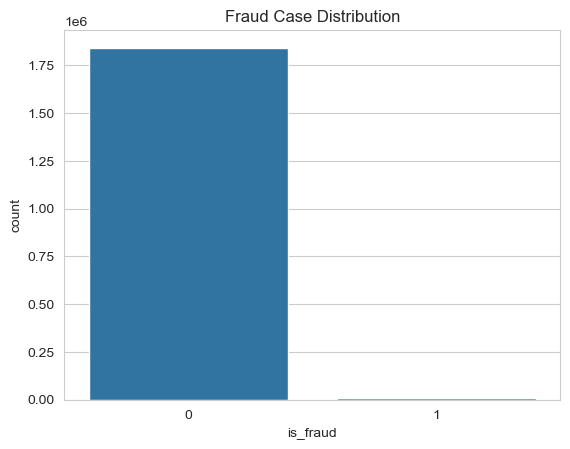

In [15]:
sns.countplot(x="is_fraud", data=df)

plt.title("Fraud Case Distribution")
plt.show()

### Interpretation

The dataset is **extremely imbalanced**. Genuine transactions number about **1.84 million**, while only **9,651 transactions (about 0.52%)** are fraudulent. The fraud bar is barely visible on the chart because of this difference.

This has an important consequence: a model that labelled every transaction as genuine would be correct about 99.5% of the time without detecting a single fraud. **Accuracy is therefore not a reliable metric for this project.** Precision, Recall, F1-Score and PR-AUC will be used for evaluation instead, and the imbalance will be handled with techniques such as SMOTE, class weights and threshold tuning.

## Relationship Between Merchant Category and Fraud

Different types of purchases carry different levels of fraud risk. To examine this, a cross-tabulation compares genuine and fraudulent transactions across t14 merchant categories. The **fraud rate (%)** is calculated for each category, so that categories can be compared fairly despite having different transaction volumes, and the table is sorted from the highest to the lowest fraud rate.

In [18]:
category_table = pd.crosstab(df["category"], df["is_fraud"])

# Calculating Fraud % for each category.
category_table["Total"] = category_table[0] + category_table[1]
category_table["Fraud Rate (%)"] = (category_table[1] / category_table["Total"] * 100).round(2)

category_table = category_table.sort_values("Fraud Rate (%)", ascending=False)
category_table

is_fraud,0,1,Total,Fraud Rate (%)
category,,,,
shopping_net,137103,2219,139322,1.59
misc_net,89472,1182,90654,1.30
grocery_pos,173963,2228,176191,1.26
shopping_pos,165407,1056,166463,0.63
gas_transport,187257,772,188029,0.41
misc_pos,113907,322,114229,0.28
grocery_net,64703,175,64878,0.27
travel,57800,156,57956,0.27
entertainment,133826,292,134118,0.22


### Interpretation

Fraud rates vary considerably across categories. Three categories stand out with rates above 1%: **shopping_net (1.59%)**, **misc_net (1.30%)** and **grocery_pos (1.26%)**. These are roughly two to three times the overall fraud rate of 0.52%. The lowest rates, about **0.15%**, appear in **health_fitness** and **home**.

Online categories (those ending in `_net`, such as shopping_net and misc_net) tend to show higher fraud rates, which is consistent with the fact that card-not-present transactions are easier to exploit. **grocery_pos** is also notable because it has the largest number of fraud cases overall (2,228).

These results suggest that **merchant category is likely to be an important predictor** and will be one-hot encoded for the models.

## Relationship Between Transaction Amount and Fraud

Fraudulent transactions may differ from genuine ones in the amount charged. To investigate this, a boxplot compares the distribution of transaction amounts for genuine and fraudulent transactions, and summary statistics are calculated for each group. Extreme outliers are hidden in the boxplot so that the central part of each distribution is clearly visible.

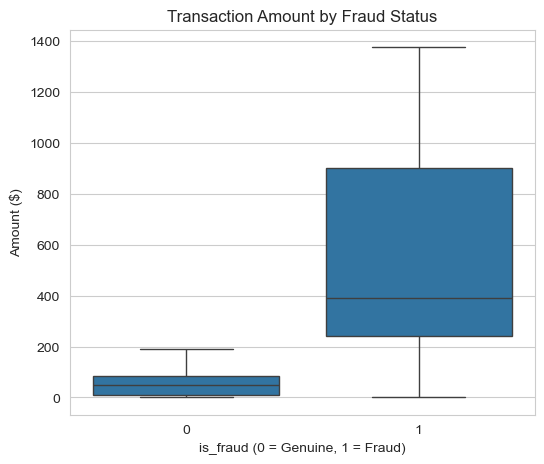

,count,mean,std,min,25%,50%,75%,max
is_fraud,,,,,,,,
0,1842743.0,67.7,153.5,1.0,9.6,47.2,82.6,28948.9
1,9651.0,530.7,391.0,1.1,240.1,390.0,902.4,1376.0


In [21]:
plt.figure(figsize=(6, 5))
sns.boxplot(x="is_fraud", y="amt", data=df, showfliers=False)
plt.title("Transaction Amount by Fraud Status")
plt.xlabel("is_fraud (0 = Genuine, 1 = Fraud)")
plt.ylabel("Amount ($)")
plt.show()

df.groupby("is_fraud")["amt"].describe().round(1)

### Interpretation

Fraudulent transactions involve much larger amounts than genuine ones. The **median fraud amount is about USD 390**, compared with about **USD 47 for genuine transactions**, roughly eight times higher. The average fraud amount (about USD 531) is also far above the genuine average (about USD 68).

Transaction amount is therefore **one of the strongest indicators of fraud** and is expected to be an important feature in the predictive models.

## Analysis of Credit Card Numbers

The credit card number (`cc_num`) identifies the customer's card. Before deciding whether to use it as a feature, its distribution is examined: how many unique cards exist, how many of them experienced fraud, and how many transactions each card made.

In [24]:
print("Total transactions                     :", len(df))
print("Unique card numbers (cc_num)           :", df["cc_num"].nunique())
print("Cards with at least one fraud case     :", df.loc[df["is_fraud"] == 1, "cc_num"].nunique())
print()

print("Transactions per card  :", df["cc_num"].value_counts())

Total transactions                     : 1852394
Unique card numbers (cc_num)           : 999
Cards with at least one fraud case     : 976

Transactions per card  : cc_num
6538441737335434       4392
30270432095985         4392
6538891242532018       4386
4364010865167176       4386
4642255475285942       4386
                       ... 
4714017207228610634       7
4352307151555405069       7
180097223252063           7
6011732631674654          7
4295296907373             6
Name: count, Length: 999, dtype: int64


### Interpretation

The dataset contains only **999 unique cards**, yet **976 of them (about 98%) were involved in at least one fraudulent transaction**. Fraud is therefore spread across almost every card, rather than being concentrated in a few compromised cards. The number of transactions per card also varies widely, from as few as 6 to over 4,000.

Since nearly every card is affected, the card number offers no way to separate risky cards from safe ones. The next analysis tests whether a card's fraud history can predict future fraud.

## Does Past Fraud on a Card Predict Future Fraud?

If a card that had fraud earlier were more likely to have fraud later, the card number could be a useful feature. To test this, the data is divided at **21 June 2020**, the date that separates the original training and testing files, and the cards are grouped according to whether fraud occurred in the earlier period, the later period, both or neither.

In [27]:
split_date = pd.Timestamp("2020-06-21 12:14:25")

# Fraud cases per card in each period
earlier = df[df["trans_date_trans_time"] < split_date].groupby("cc_num")["is_fraud"].sum()
later = df[df["trans_date_trans_time"] >= split_date].groupby("cc_num")["is_fraud"].sum()

cards = pd.concat([earlier, later], axis=1, join="inner")
cards.columns = ["fraud_earlier", "fraud_later"]

print("Cards with fraud in BOTH periods :", ((cards["fraud_earlier"] > 0) & (cards["fraud_later"] > 0)).sum())
print("Cards with fraud ONLY earlier    :", ((cards["fraud_earlier"] > 0) & (cards["fraud_later"] == 0)).sum())
print("Cards with fraud ONLY later      :", ((cards["fraud_earlier"] == 0) & (cards["fraud_later"] > 0)).sum())
print("Cards with no fraud in either    :", ((cards["fraud_earlier"] == 0) & (cards["fraud_later"] == 0)).sum())

Cards with fraud in BOTH periods : 4
Cards with fraud ONLY earlier    : 683
Cards with fraud ONLY later      : 198
Cards with no fraud in either    : 23


### Interpretation

Of the 908 cards that appear in both periods, only **4 cards had fraud in both periods**. In contrast, **683 cards had fraud only in the earlier period** and **198 only in the later period**. Fraud on a card in one period therefore does not indicate fraud in the other. This suggests that fraud on a given card tends to occur in a limited time window instead of continuing indefinitely.

In addition, card numbers cannot generalise to **newly issued cards** that the model has never seen. For these reasons, `cc_num` carries no reusable fraud pattern and is **dropped from the model**, so the models learn from transaction characteristics rather than from individual cards.

### Key EDA Findings

- Fraud is extremely rare (about 0.52% of transactions), so accuracy cannot be trusted.
- Online (`_net`) categories and grocery point-of-sale transactions have the highest fraud rates.
- Fraudulent transactions are much larger than genuine ones (median about $390 vs about $47).
- Fraud is spread across almost all cards and does not repeat reliably on the same card, so the card number is not used as a feature.

# 6. Data Preprocessing

## Missing Value Analysis

Before preparing the data for machine learning, it is essential to check whether any features contain missing values. Missing data can reduce model performance, introduce bias and cause errors during training if it is not handled properly. The number of missing values in every column is calculated to assess the completeness of the dataset.

In [31]:
df.isnull().sum()

trans_date_trans_time    0
cc_num                   0
merchant                 0
category                 0
amt                      0
first                    0
last                     0
gender                   0
street                   0
city                     0
state                    0
zip                      0
lat                      0
long                     0
city_pop                 0
job                      0
dob                      0
trans_num                0
unix_time                0
merch_lat                0
merch_long               0
is_fraud                 0
dtype: int64

### Interpretation

The analysis shows **no missing values in any of the 22 columns**, so the dataset is complete and no imputation or removal of records is required. This is a significant advantage for a dataset of this size, as every one of the 1,852,394 transactions can be used for modelling.

In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1852394 entries, 0 to 1852393
Data columns (total 22 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   trans_date_trans_time  datetime64[ns]
 1   cc_num                 int64         
 2   merchant               object        
 3   category               object        
 4   amt                    float64       
 5   first                  object        
 6   last                   object        
 7   gender                 object        
 8   street                 object        
 9   city                   object        
 10  state                  object        
 11  zip                    int64         
 12  lat                    float64       
 13  long                   float64       
 14  city_pop               int64         
 15  job                    object        
 16  dob                    datetime64[ns]
 17  trans_num              object        
 18  unix_time             

### Interpretation

The dataset contains **1,852,394 records and 22 columns**, with two datetime columns (`trans_date_trans_time` and `dob`), ten categorical (`object`) columns, five integer columns and five floating-point columns. All data types are now appropriate. The categorical columns will be encoded numerically, and the datetime columns will be used to create new features.

# 7. Feature Selection

Before training the models, columns that do not help to predict fraud, or that could harm the model's ability to generalise, are removed. The following columns are dropped:

- **`cc_num`**: identifies individual cards. The EDA showed that it carries no reusable fraud pattern and cannot generalise to newly issued cards.
- **`first`, `last`, `street`**: personal identifiers that are specific to individual customers.
- **`trans_num`**: a unique transaction ID that is different for every row and has no predictive meaning.
- **`zip`**: duplicates the location information already available in the `city` and `state` columns and the coordinates.
- **`city_pop`**: describes the customer's home town and largely overlaps with the location variables that are retained.
- **`unix_time`**: only repeats the transaction time already stored in `trans_date_trans_time`.

Dropping identifiers also reduces the risk of the models memorising individual customers instead of learning general fraud patterns.

In [36]:
model_df = df.drop(columns=["first", "last", "street", "zip", "city_pop", "trans_num", "unix_time", "cc_num"], errors="ignore")

model_df

,trans_date_trans_time,merchant,category,amt,gender,city,state,lat,long,job,dob,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,"fraud_Rippin, Kub and Mann",misc_net,4.97,F,Moravian Falls,NC,36.0788,-81.1781,"Psychologist, counselling",1988-03-09,36.011293,-82.048315,0
1,2019-01-01 00:00:44,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,F,Orient,WA,48.8878,-118.2105,Special educational needs teacher,1978-06-21,49.159047,-118.186462,0
2,2019-01-01 00:00:51,fraud_Lind-Buckridge,entertainment,220.11,M,Malad City,ID,42.1808,-112.2620,Nature conservation officer,1962-01-19,43.150704,-112.154481,0
3,2019-01-01 00:01:16,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,M,Boulder,MT,46.2306,-112.1138,Patent attorney,1967-01-12,47.034331,-112.561071,0
4,2019-01-01 00:03:06,fraud_Keeling-Crist,misc_pos,41.96,M,Doe Hill,VA,38.4207,-79.4629,Dance movement psychotherapist,1986-03-28,38.674999,-78.632459,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1852389,2020-12-31 23:59:07,fraud_Reilly and Sons,health_fitness,43.77,M,Luray,MO,40.4931,-91.8912,Town planner,1966-02-13,39.946837,-91.333331,0
1852390,2020-12-31 23:59:09,fraud_Hoppe-Parisian,kids_pets,111.84,M,Lake Jackson,TX,29.0393,-95.4401,Futures trader,1999-12-27,29.661049,-96.186633,0
1852391,2020-12-31 23:59:15,fraud_Rau-Robel,kids_pets,86.88,F,Burbank,WA,46.1966,-118.9017,Musician,1981-11-29,46.658340,-119.715054,0
1852392,2020-12-31 23:59:24,fraud_Breitenberg LLC,travel,7.99,M,Mesa,ID,44.6255,-116.4493,Cartographer,1965-12-15,44.470525,-117.080888,0


# 8. Feature Engineering

New features are created from the existing columns, to give the models information that is easier to learn from than the raw values:

- **`hour`, `day_of_week` and `month`**: extracted from the transaction time, to capture when fraud tends to occur.
- **`age`**: the customer's age at the time of the transaction, calculated from the date of birth.
- **`distance_km`**: the distance between the customer's home and the merchant, calculated from their coordinates using the **Haversine formula**, which measures distance along the Earth's surface. Transactions far from the customer's home may be suspicious.

The transaction timestamps are saved in a separate variable (`trans_time`) before being dropped, because they are needed later for the chronological train-test split. The original timestamp, date of birth and coordinate columns are then removed, since their information is now captured by the new features.

In [38]:
model_df["hour"] = model_df["trans_date_trans_time"].dt.hour
model_df["day_of_week"] = model_df["trans_date_trans_time"].dt.day_name()
model_df["month"] = model_df["trans_date_trans_time"].dt.month_name()

# Customer's age 
model_df["age"] = ((model_df["trans_date_trans_time"] - model_df["dob"]).dt.days // 365.25).astype(int)

# Distance (km) between customer's home and merchant 
lat1, lon1 = np.radians(model_df["lat"]), np.radians(model_df["long"])
lat2, lon2 = np.radians(model_df["merch_lat"]), np.radians(model_df["merch_long"])

a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
model_df["distance_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))

# Saving the transaction timestamps for the date-based split later
trans_time = model_df["trans_date_trans_time"].copy()

model_df = model_df.drop(columns=["trans_date_trans_time", "dob", "lat", "long", "merch_lat", "merch_long"], errors="ignore")

model_df

,merchant,category,amt,gender,city,state,job,is_fraud,hour,day_of_week,month,age,distance_km
0,"fraud_Rippin, Kub and Mann",misc_net,4.97,F,Moravian Falls,NC,"Psychologist, counselling",0,0,Tuesday,January,30,78.597568
1,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,F,Orient,WA,Special educational needs teacher,0,0,Tuesday,January,40,30.212176
2,fraud_Lind-Buckridge,entertainment,220.11,M,Malad City,ID,Nature conservation officer,0,0,Tuesday,January,56,108.206083
3,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,M,Boulder,MT,Patent attorney,0,0,Tuesday,January,51,95.673231
4,fraud_Keeling-Crist,misc_pos,41.96,M,Doe Hill,VA,Dance movement psychotherapist,0,0,Tuesday,January,32,77.556744
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1852389,fraud_Reilly and Sons,health_fitness,43.77,M,Luray,MO,Town planner,0,23,Thursday,December,54,77.026148
1852390,fraud_Hoppe-Parisian,kids_pets,111.84,M,Lake Jackson,TX,Futures trader,0,23,Thursday,December,21,100.074420
1852391,fraud_Rau-Robel,kids_pets,86.88,F,Burbank,WA,Musician,0,23,Thursday,December,39,80.759302
1852392,fraud_Breitenberg LLC,travel,7.99,M,Mesa,ID,Cartographer,0,23,Thursday,December,55,52.933240


## Grouping the Hour of the Day

The 24 individual hours are grouped into four six-hour periods: **0-5** (night), **6-11** (morning), **12-17** (afternoon) and **18-23** (evening). Grouping reduces the number of categories to encode and makes the pattern easier to interpret. A table and a bar chart then show the fraud rate in each period.

In [40]:
hour_bins = [-1, 5, 11, 17, 23]
hour_labels = ["0-5", "6-11", "12-17", "18-23"]

model_df["hour_group"] = pd.cut(model_df["hour"], bins=hour_bins, labels=hour_labels)
model_df = model_df.drop(columns=["hour"])

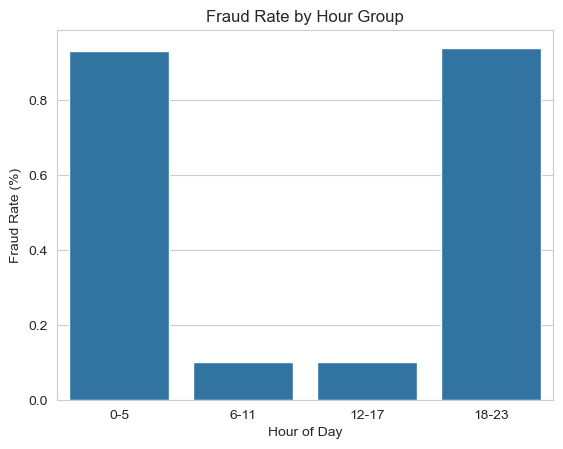

In [41]:
hour_table = pd.crosstab(model_df["hour_group"], model_df["is_fraud"])

hour_table["Total"] = hour_table[0] + hour_table[1]
hour_table["Fraud Rate (%)"] = (hour_table[1] / hour_table["Total"] * 100).round(2)

sns.barplot(x=hour_table.index, y=hour_table["Fraud Rate (%)"])
plt.title("Fraud Rate by Hour Group")
plt.xlabel("Hour of Day")
plt.ylabel("Fraud Rate (%)")
plt.show()

### Interpretation

Fraud is strongly linked to the time of day. The fraud rate is about **0.93% between 0:00 and 5:59** and **0.94% between 18:00 and 23:59**, compared with only about **0.10% in the morning and afternoon**. Fraud is therefore roughly **nine times more likely** during the night and evening.

Time of day is expected to be a useful predictor, so it is retained as a categorical feature.

## Inspecting the Categorical Features

The number of unique values in each column is examined to decide how each variable should be encoded. Variables with only a few categories can be converted into binary columns (one-hot encoding), but variables with hundreds of categories would create too many columns and need a different approach.

In [44]:
unique_counts = pd.DataFrame({
    "dtype": model_df.dtypes,
    "unique_values": model_df.nunique()
}).sort_values("unique_values")

unique_counts

,dtype,unique_values
gender,object,2
is_fraud,int64,2
hour_group,category,4
day_of_week,object,7
month,object,12
category,object,14
state,object,51
age,int32,84
job,object,497
merchant,object,693


### Interpretation

The variables fall into three groups:

- **Low cardinality**: `gender` (2), `hour_group` (4), `day_of_week` (7), `month` (12) and `category` (14). These are suitable for **one-hot encoding**.
- **High cardinality**: `state` (51), `job` (497), `merchant` (693) and `city` (906). One-hot encoding these would add over 2,000 columns to a dataset of 1.85 million rows, so they will be handled with **target encoding** after the train-test split.
- **Numerical**: `amt`, `age` and `distance_km`, which can be used as they are, after scaling where needed.

# 9. Feature Matrix and Target Variable Preparation

The dataset is divided into two components: the **feature matrix (`X`)**, containing all predictor variables, and the **target variable (`y`)**, containing the `is_fraud` labels that the models will learn to predict. The dimensions and data type of the target are checked to confirm that both are correctly aligned.

In [47]:
X = model_df.drop("is_fraud", axis=1)
y = model_df["is_fraud"]
print(X.shape)
print(y.shape)

(1852394, 12)
(1852394,)


In [48]:
print(y.dtype)
print(y.unique())

int64
[0 1]


### Interpretation

The feature matrix contains **1,852,394 observations and 12 predictor variables**, and the target variable contains the same number of labels, confirming that they are properly aligned. The target is already stored as integers with two values, **0 (genuine)** and **1 (fraud)**, so no label conversion is needed, unlike the churn project's Yes/No labels.

The categorical predictors are encoded in the next section.

# 10. One-Hot Encoding of Low-Cardinality Categorical Variables

Machine learning algorithms require numerical inputs, so categorical predictors must be converted into numbers. Variables with a small number of categories (`gender`, `category`, `day_of_week`, `month` and `hour_group`) are transformed using **One-Hot Encoding**, which creates a separate binary (0/1) column for each category. The `drop_first=True` option removes one redundant column per variable, to avoid multicollinearity.

The high-cardinality variables (`state`, `city`, `job` and `merchant`) are handled separately using **Target Encoding** after the train-test split. One-hot encoding is safe to perform before the split because it does not use the target variable.

In [51]:
X = pd.get_dummies(X, columns= ["gender", "category", "day_of_week", "month", "hour_group"], drop_first=True, dtype=int)

print(X.shape)
X.head()

(1852394, 41)


,merchant,amt,city,state,job,age,distance_km,gender_M,category_food_dining,category_gas_transport,...,month_July,month_June,month_March,month_May,month_November,month_October,month_September,hour_group_6-11,hour_group_12-17,hour_group_18-23
0,"fraud_Rippin, Kub and Mann",4.97,Moravian Falls,NC,"Psychologist, counselling",30,78.597568,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,"fraud_Heller, Gutmann and Zieme",107.23,Orient,WA,Special educational needs teacher,40,30.212176,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,fraud_Lind-Buckridge,220.11,Malad City,ID,Nature conservation officer,56,108.206083,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,"fraud_Kutch, Hermiston and Farrell",45.00,Boulder,MT,Patent attorney,51,95.673231,1,0,1,...,0,0,0,0,0,0,0,0,0,0
4,fraud_Keeling-Crist,41.96,Doe Hill,VA,Dance movement psychotherapist,32,77.556744,1,0,0,...,0,0,0,0,0,0,0,0,0,0


### Interpretation

The encoding was completed successfully. The feature matrix still contains **1,852,394 transactions**, while the number of predictor variables increased from **12 to 41**. The five encoded variables were replaced by **34 binary columns**: 1 for gender, 13 for category, 6 for day of week, 11 for month and 3 for hour group.

The preview confirms that the new columns contain only 0 and 1, where 1 marks the category a transaction belongs to. The remaining categorical variables (`state`, `city`, `job` and `merchant`) and the numerical variables (`amt`, `age` and `distance_km`) are unchanged and are processed in the next steps.ble.

# 11. Chronological Train-Test Split

The dataset is divided into training and testing subsets **by transaction date** rather than at random. All transactions **before 21 June 2020** are used for training, and all later transactions are reserved for testing. This mirrors real-world fraud detection, where a model is trained on past transactions and must detect fraud in future, unseen transactions. A random split would let the model learn from transactions that occur after those it is tested on, giving unrealistically optimistic results.

The split is carried out **before target encoding**, so that fraud rates for categories such as merchant and job are calculated from the training data only, which prevents target leakage.

In [54]:
split_date = pd.Timestamp("2020-06-21 12:14:25")
train_mask = trans_time < split_date

X_train, X_test = X[train_mask].copy(), X[~train_mask].copy()
y_train, y_test = y[train_mask], y[~train_mask]

print(X_train.shape, X_test.shape)

(1296675, 41) (555719, 41)


In [55]:
print("Fraud cases  - train:", y_train.sum(), "| test:", y_test.sum())
print("Fraud rate % - train:", round(y_train.mean() * 100, 3), "| test:", round(y_test.mean() * 100, 3))

Fraud cases  - train: 7506 | test: 2145
Fraud rate % - train: 0.579 | test: 0.386


### Interpretation

The chronological split produced a training set of **1,296,675 transactions (70%)** and a test set of **555,719 transactions (30%)**, each with 41 features. This is identical to the original training and testing files supplied with the dataset.

The training set contains **7,506 fraudulent transactions (0.579%)**, while the test set contains **2,145 (0.386%)**. Both sets remain extremely imbalanced, and the fraud rate is noticeably lower in the test period, which is typical of real-world data, where fraud patterns change over time. For this reason, model performance is judged using Precision, Recall, F1-Score and PR-AUC rather than accuracy, and the test results should be read with this shift in mind.

# 12. Target Encoding of High-Cardinality Variables

The variables `state`, `city`, `job` and `merchant` have too many categories for one-hot encoding. **Target Encoding** replaces each category with the **fraud rate observed for that category** in the training data, so that each variable is represented by a single numerical column. For example, a merchant with a high historical fraud rate receives a high value.

Three precautions are used to avoid leakage and overfitting:

- The encoder is **fitted on the training data only**, and the same learned values are then applied to the test data.
- With `cv=5`, the encoding of the training data is computed with **5-fold cross-fitting**, so that no transaction's encoded value is calculated from its own fraud label.
- `smooth="auto"` pulls the values for rare categories towards the overall fraud rate, so that a category with only a few transactions does not receive an extreme value by chance.

In [58]:
from sklearn.preprocessing import TargetEncoder

te_cols = ["state", "city", "job", "merchant"]

encoder = TargetEncoder(target_type="binary", smooth="auto", cv=5, random_state=42)

X_train[te_cols] = encoder.fit_transform(X_train[te_cols], y_train)  
X_test[te_cols]  = encoder.transform(X_test[te_cols])                 

In [59]:
X_train.dtypes.value_counts()

int32      35
float64     6
Name: count, dtype: int64

### Interpretation

After encoding, all 41 features in the training set are numerical: **35 integer columns** (the 34 one-hot columns and `age`) and **6 floating-point columns** (`amt`, `distance_km` and the four target-encoded variables). The data is now fully numerical and compatible with all the machine learning models used in this project.

# 13. Feature Scaling

Logistic Regression is sensitive to the scale of the features, so the numerical columns (`amt`, `age`, `distance_km` and the four target-encoded variables) are **standardised** using `StandardScaler`, which transforms each column to have a mean of 0 and a standard deviation of 1. Without scaling, a variable with large values such as `amt` would dominate variables with small values.

As with the encoder, the scaler is **fitted on the training data only** and then applied to the test data, so that no information from the test set influences the training process. The binary one-hot columns do not need scaling.

Scaled copies of the data (`X_train_scaled` and `X_test_scaled`) are created for **Logistic Regression** (and for SMOTE later). Tree-based models such as **Random Forest and XGBoost** are not affected by feature scale and use the original, unscaled data.

In [62]:
from sklearn.preprocessing import StandardScaler

scale_cols = ["amt", "age", "distance_km", "state", "city", "job", "merchant"]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scale_cols] = scaler.fit_transform(X_train[scale_cols])   
X_test_scaled[scale_cols] = scaler.transform(X_test[scale_cols])         

# 14. Logistic Regression

Logistic Regression is a linear classification model that estimates the probability that a transaction is fraudulent. A transaction is labelled as fraud when this probability reaches the default threshold of 0.50. It is simple, fast and easy to interpret, so it is used as the **baseline model**, against which the more advanced models are compared.

The model is trained on the scaled training data, and its predictions are then generated for the unseen test set (future transactions).

In [64]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [65]:
y_pred_lr = lr.predict(X_test_scaled)

In [66]:
from sklearn.metrics import accuracy_score

print("Accuracy:", accuracy_score(y_test, y_pred_lr))

Accuracy: 0.9958018351001136


In [67]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_lr)
print(cm)

[[553370    204]
 [  2129     16]]


In [68]:
from sklearn.metrics import precision_score

print("Precision:", precision_score(y_test, y_pred_lr))

Precision: 0.07272727272727272


In [69]:
from sklearn.metrics import recall_score

print("Recall:", recall_score(y_test, y_pred_lr))

Recall: 0.007459207459207459


In [70]:
from sklearn.metrics import f1_score

print("F1 Score:", f1_score(y_test, y_pred_lr))

F1 Score: 0.013530655391120507


## Interpretation

The baseline Logistic Regression achieved an **accuracy** of 99.58%, but this figure is misleading. The **test set** contains only **2,145 fraudulent** transactions out of **555,719 (0.39%)**, so a model that labels every transaction as genuine would score about 99.61%. Accuracy therefore says almost nothing about fraud detection here.

The **confusion matrix** shows that the model correctly identified 553,370 genuine transactions and only 16 fraudulent transactions, while missing 2,129 frauds (False Negatives) and raising 204 false alarms (False Positives). The **precision of 7.27%** means that only about one in fourteen flagged transactions was actually fraudulent. The **recall of 0.75%** means the model detected less than 1% of real fraud, and the resulting **F1-score of 0.0135** confirms poor overall performance.

The model performs poorly mainly because of the extreme class imbalance (0.58% fraud in the training data). Trained on default settings, it learns to predict low fraud probabilities for nearly all transactions, so very few exceed the default 0.50 threshold. In addition, Logistic Regression is a linear model and may not capture the complex feature interactions that characterise fraud. This baseline serves as a benchmark. The next steps are to handle class imbalance, tune the decision threshold, and compare with tree-based models such as Random Forest and XGBoost.

# 15. Random Forest Classifier

A Random Forest builds many decision trees, each trained on a random sample of the data and features, and combines their votes into the final prediction. Unlike Logistic Regression, it can capture **non-linear relationships and interactions** between features, which makes it well suited to fraud detection. It also does not require feature scaling, so it is trained on the original, unscaled data.

The model uses **100 trees** and requires at least **5 transactions in each leaf** (`min_samples_leaf=5`), which stops the trees from memorising individual transactions. 

In [73]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

RandomForestClassifier(min_samples_leaf=5, n_jobs=-1, random_state=42)

In [74]:
y_pred_rf = rf.predict(X_test)

In [75]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))
print()
print(confusion_matrix(y_test, y_pred_rf))

Accuracy : 0.9975113321660768
Precision: 0.9359267734553776
Recall   : 0.38135198135198134
F1 Score : 0.5419012918184829

[[553518     56]
 [  1327    818]]


### Interpretation

The Random Forest achieved an accuracy of **99.75%**, a precision of **93.59%**, a recall of **38.14%** and an F1-score of **54.19%**. The confusion matrix shows that the model detected **818 fraudulent transactions**, missed **1,327**, and wrongly flagged only **56** genuine transactions.

This is a large improvement over the Logistic Regression baseline (recall 0.75%, F1-score 0.0135). The model is highly reliable when it raises an alert: about **94 of every 100 flagged transactions are genuinely fraudulent**. However, it still detects fewer than 4 in 10 frauds. This suggests that the default 0.50 threshold is too strict for such imbalanced data, because many fraudulent transactions receive fraud probabilities just below it. The class imbalance techniques and threshold tuning in the following sections address this.

# 16. Hyperparameter Tuning using GridSearchCV

Hyperparameters are model settings chosen before training, such as the depth of the trees. **GridSearchCV** tests every combination from a grid of candidate values and selects the best combination using cross-validation, where the training data is split into several parts and the model is repeatedly trained on some parts and validated on the rest.

The following values are tested:

- **`max_depth`**: 10 and 20 (how deep each tree can grow).
- **`min_samples_leaf`**: 5 and 20 (the minimum number of transactions in a leaf).

The scoring metric is the **F1-score**, because accuracy is unreliable for imbalanced data. To keep the search fast, tuning is carried out on a **random sample of 200,000 training transactions** with 3-fold cross-validation. The best settings are then used to retrain the model on the full training set.

In [78]:
X_sample = X_train.sample(n=200000, random_state=42)
y_sample = y_train.loc[X_sample.index]

In [79]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "max_depth": [10, 20],
    "min_samples_leaf": [5, 20]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    param_grid=param_grid,
    cv=3,
    scoring="f1"
)

grid_search.fit(X_sample, y_sample)

GridSearchCV(cv=3, estimator=RandomForestClassifier(n_jobs=-1, random_state=42),
             param_grid={'max_depth': [10, 20], 'min_samples_leaf': [5, 20]},
             scoring='f1')

In [80]:
print("Best parameters:", grid_search.best_params_)
print("Best CV F1-score:", grid_search.best_score_)

Best parameters: {'max_depth': 20, 'min_samples_leaf': 5}
Best CV F1-score: 0.6969765527914671


### Interpretation

The search selected **`max_depth = 20`** and **`min_samples_leaf = 5`**, with a cross-validated F1-score of **0.697**. This suggests that deeper trees with small leaves, which can capture more detailed fraud patterns, work better than shallower, more heavily constrained ones.

In [82]:
best_rf = grid_search.best_estimator_
best_rf.fit(X_train, y_train)      

y_pred_best = best_rf.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best))
print("Recall   :", recall_score(y_test, y_pred_best))
print("F1 Score :", f1_score(y_test, y_pred_best))
print()
print(confusion_matrix(y_test, y_pred_best))

Accuracy : 0.9972953956945867
Precision: 0.9349593495934959
Recall   : 0.32167832167832167
F1 Score : 0.4786680541103018

[[553526     48]
 [  1455    690]]


### Interpretation

On the test set, the tuned Random Forest achieved an accuracy of **99.73%**, a precision of **93.50%**, a recall of **32.17%** and an F1-score of **47.87%**. It detected **690 frauds**, missed **1,455** and raised **48 false alarms**.

This is slightly **worse** than the baseline Random Forest (recall 38.14%, F1-score 54.19%), even though the cross-validation score was 0.70. There are two likely reasons:

- **The cross-validation was done on a random sample** that mixes all time periods, whereas the test set contains future transactions with a lower fraud rate. Scores from shuffled data can therefore be too optimistic.
- **The grid only tested depths of 10 and 20**, while the baseline model had no depth limit, so the search could not find the baseline's configuration.

Tuning did not improve performance, so the baseline Random Forest remains the better version. The main weakness of both models is low recall, which is addressed by handling class imbalance and tuning the decision threshold.

# 17. XGBoost Classifier

XGBoost (Extreme Gradient Boosting) builds decision trees **one after another**, where each new tree focuses on correcting the mistakes made by the previous trees. This sequential learning often gives it higher accuracy than a Random Forest, where the trees are built independently, and it is widely used for fraud detection on tabular data. Like Random Forest, it does not need scaled features, so it is trained on the original data.

The model uses **100 trees** (`n_estimators=100`), a **learning rate of 0.1** that controls how strongly each tree corrects the previous ones, and a **maximum tree depth of 6** to limit overfitting. 

In [85]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    n_jobs=-1
)
xgb.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=-1, num_parallel_tree=None, ...)

In [86]:
y_pred_xgb = xgb.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred_xgb))
print("Precision:", precision_score(y_test, y_pred_xgb))
print("Recall   :", recall_score(y_test, y_pred_xgb))
print("F1 Score :", f1_score(y_test, y_pred_xgb))
print()
print(confusion_matrix(y_test, y_pred_xgb))

Accuracy : 0.9970200766934368
Precision: 0.766050054406964
Recall   : 0.3282051282051282
F1 Score : 0.4595300261096606

[[553359    215]
 [  1441    704]]


### Interpretation

XGBoost achieved an accuracy of **99.70%**, a precision of **76.61%**, a recall of **32.82%** and an F1-score of **45.95%**. It correctly detected **704 fraudulent transactions**, missed **1,441**, and raised **215 false alarms**.

Compared with the Random Forest (precision 93.59%, recall 38.14%, F1-score 54.19%), XGBoost produced more false alarms and detected fewer frauds, so with these default settings it did not outperform the Random Forest. Like the other models, it still misses about two-thirds of the fraud at the default 0.50 threshold, because the class imbalance leads the model to assign low fraud probabilities. This motivates the class imbalance techniques and threshold tuning in the next sections.

# 18. Handling Class Imbalance using SMOTE

Fraud makes up only about 0.58% of the training data, so models tend to ignore it and predict "genuine" almost every time. **SMOTE (Synthetic Minority Over-sampling Technique)** addresses this by creating new, synthetic fraud examples. For a chosen fraud transaction, it finds similar fraud transactions (its nearest neighbours) and creates a new point at a random position between them. This gives the model a broader and denser picture of what fraud looks like, without simply duplicating existing rows.

Important points about how it is applied here:

- SMOTE is applied **only to the training data**. The test set is left untouched, so it keeps its real fraud rate and the results remain honest.
- It is applied to the **scaled** training data, because SMOTE measures distances between transactions, and all features must be on a comparable scale.
- A **partial balance** is used (`sampling_strategy=0.1`), so that the number of frauds becomes 10% of the number of genuine transactions. A full 1:1 balance would create more than a million synthetic rows and make training very slow.

In [89]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(sampling_strategy=0.1, random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

C:\Users\ishik\Downloads\New folder\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\ishik\Downloads\New folder\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\ishik\Downloads\New folder\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\ishik\Downloads\New folder\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\ishik\Downloads\New folder\Lib\subprocess.py", line 1538, in 

In [90]:
print("Before SMOTE:")
print(y_train.value_counts())
print()
print("After SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
is_fraud
0    1289169
1       7506
Name: count, dtype: int64

After SMOTE:
is_fraud
0    1289169
1     128916
Name: count, dtype: int64


### Interpretation

Before SMOTE, the training data contained **1,289,169 genuine transactions and only 7,506 frauds**. After SMOTE, the number of frauds increased to **128,916**, which is 10% of the genuine count, by adding about **121,000 synthetic fraud transactions**. The number of genuine transactions is unchanged, and the training set grew from about 1.30 million to 1.42 million rows. The model now sees 1 fraud for every 10 genuine transactions, instead of 1 in 172.

### Logistic Regression with SMOTE

A new Logistic Regression model is trained on the SMOTE-balanced training data and evaluated on the **original, untouched test set**. Its results can therefore be compared directly with the baseline Logistic Regression.

In [93]:
lr_smote = LogisticRegression(max_iter=1000)
lr_smote.fit(X_train_smote, y_train_smote)

y_pred_smote = lr_smote.predict(X_test_scaled)

print("Accuracy :", accuracy_score(y_test, y_pred_smote))
print("Precision:", precision_score(y_test, y_pred_smote))
print("Recall   :", recall_score(y_test, y_pred_smote))
print("F1 Score :", f1_score(y_test, y_pred_smote))
print()
print(confusion_matrix(y_test, y_pred_smote))

Accuracy : 0.9938116206212132
Precision: 0.26265590608950845
Recall   : 0.3337995337995338
F1 Score : 0.29398480804762883

[[551564   2010]
 [  1429    716]]


### Interpretation

After SMOTE, the Logistic Regression model achieved an accuracy of **99.38%**, a precision of **26.27%**, a recall of **33.38%** and an F1-score of **29.40%**. It detected **716 frauds**, missed **1,429**, and raised **2,010 false alarms**.

This is a major improvement over the baseline, where recall was 0.75% and the F1-score was 0.0135. **Recall rose about 45 times and the F1-score about 22 times**, and precision also improved (from 7.3% to 26.3%). The cost is that false alarms increased from 204 to 2,010, and accuracy fell slightly from 99.58% to 99.38%, which is acceptable because accuracy is not a reliable measure here.

Because SMOTE was applied only to the training data and the model was tested on real, unseen transactions, this improvement is genuine. The model still misses about two-thirds of the frauds. This suggests that a linear model cannot fully capture fraud patterns even when more fraud examples are available. One limitation of SMOTE is that it can create fractional values in the one-hot (0/1) columns of the synthetic rows, which does not reflect real transactions.

# 19. Cost-Sensitive Learning using Class Weights

SMOTE changes the data by adding synthetic frauds. **Class weights** take a different approach: the data stays as it is, but mistakes on the rare class are made **more expensive** during training. Normally, every transaction counts equally, so ignoring the few fraud cases hardly increases the total error. With class weights, each fraud case is multiplied by a larger number, so missing a fraud becomes a much costlier mistake than raising a false alarm, and the model is forced to take fraud seriously.

Setting `class_weight="balanced"` calculates the weights automatically from the class frequencies: about **0.50 for each genuine transaction** and about **86 for each fraudulent transaction**, so one fraud counts roughly 172 times as much as one genuine transactged.

## Logistic Regression with Class Weights

A Logistic Regression model is trained on the scaled training data using balanced class weights, and evaluated on the original test set.

In [96]:
lr_weighted = LogisticRegression(max_iter=1000, class_weight="balanced")
lr_weighted.fit(X_train_scaled, y_train)

y_pred_weighted = lr_weighted.predict(X_test_scaled)

print("Accuracy :", accuracy_score(y_test, y_pred_weighted))
print("Precision:", precision_score(y_test, y_pred_weighted))
print("Recall   :", recall_score(y_test, y_pred_weighted))
print("F1 Score :", f1_score(y_test, y_pred_weighted))
print()
print(confusion_matrix(y_test, y_pred_weighted))

Accuracy : 0.9195546670169636
Precision: 0.03304660756604933
Recall   : 0.7020979020979021
F1 Score : 0.06312215772156674

[[509508  44066]
 [   639   1506]]


### Interpretation

With balanced class weights, the model achieved a recall of **70.21%**, detecting **1,506 of the 2,145 frauds**, the highest recall of any Logistic Regression variant. However, precision fell to **3.30%** and the F1-score to **6.31%**, because the model raised **44,066 false alarms**. Accuracy dropped to 91.96%.

The weight of about 86 on the fraud class made the model very aggressive: for every real fraud caught, roughly 29 genuine transactions were flagged. This is rarely practical, because every false alarm costs analyst time and may block a genuine customer. Class weights alone therefore push the model too far towards recall, and the balance needs to be refined by tuning the decision threshold.

## Random Forest with Class Weights

The same balanced class weights are applied to the Random Forest. All other settings are identical to the original Random Forest (100 trees, minimum 5 transactions per leaf), so any change in performance is due to the weighting alone.

In [99]:
rf_weighted = RandomForestClassifier(
    n_estimators=100,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf_weighted.fit(X_train, y_train)

y_pred_rf_w = rf_weighted.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred_rf_w))
print("Precision:", precision_score(y_test, y_pred_rf_w))
print("Recall   :", recall_score(y_test, y_pred_rf_w))
print("F1 Score :", f1_score(y_test, y_pred_rf_w))
print()
print(confusion_matrix(y_test, y_pred_rf_w))

Accuracy : 0.9960159721010079
Precision: 0.4474885844748858
Recall   : 0.13706293706293707
F1 Score : 0.20985010706638116

[[553211    363]
 [  1851    294]]


### Interpretation

With class weights, the Random Forest achieved an accuracy of **99.60%**, a precision of **44.75%**, a recall of **13.71%** and an F1-score of **20.99%**. It detected **294 frauds**, missed **1,851**, and raised **363 false alarms**.

Unexpectedly, this is **worse** than the unweighted Random Forest (precision 93.59%, recall 38.14%, F1-score 54.19%), with lower recall and lower precision. A possible explanation is that the very large weight makes the trees concentrate on the specific fraud cases in the training period, so they learn patterns that do not carry over to the later test period, in which fraud behaviour differs. Class weights therefore did not help the Random Forest, which was already able to rank fraudulent transactions reasonably well without them.

## XGBoost with Class Weights

XGBoost does not have a `class_weight` option. Instead it uses **`scale_pos_weight`**, which multiplies the importance of the fraud class. It is set to the number of genuine transactions divided by the number of fraudulent transactions in the training data, which works out at about **172**. All other settings are identical to the original XGBoost model.

In [102]:
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight:", scale_weight)

scale_pos_weight: 171.75179856115108


In [103]:
xgb_weighted = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    scale_pos_weight=scale_weight,
    random_state=42,
    n_jobs=-1
)
xgb_weighted.fit(X_train, y_train)

y_pred_xgb_w = xgb_weighted.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred_xgb_w))
print("Precision:", precision_score(y_test, y_pred_xgb_w))
print("Recall   :", recall_score(y_test, y_pred_xgb_w))
print("F1 Score :", f1_score(y_test, y_pred_xgb_w))
print()
print(confusion_matrix(y_test, y_pred_xgb_w))

Accuracy : 0.9768660060210286
Precision: 0.05307518985229075
Recall   : 0.2965034965034965
F1 Score : 0.09003397508493771

[[542227  11347]
 [  1509    636]]


### Interpretation

With `scale_pos_weight` of about 172, XGBoost achieved an accuracy of **97.69%**, a precision of **5.31%**, a recall of **29.65%** and an F1-score of **9.00%**. It detected **636 frauds**, missed **1,509**, and raised **11,347 false alarms**.

This is **worse** than the unweighted XGBoost (precision 76.61%, recall 32.82%, F1-score 45.95%): false alarms increased from 215 to more than 11,000, while recall did not improve. The large weight appears to have made the model over-sensitive to the training frauds, so it flags many genuine transactions without finding more real fraud in the test period.

### Summary of Class Weights

| Model | Precision | Recall | F1-Score |
|---|---|---|---|
| Logistic Regression (baseline) | 7.27% | 0.75% | 1.35% |
| Logistic Regression + Class Weights | 3.30% | 70.21% | 6.31% |
| Random Forest (baseline) | 93.59% | 38.14% | 54.19% |
| Random Forest + Class Weights | 44.75% | 13.71% | 20.99% |
| XGBoost (baseline) | 76.61% | 32.82% | 45.95% |
| XGBoost + Class Weights | 5.31% | 29.65% | 9.00% |

Class weights raised recall only for Logistic Regression, and at a very high cost in false alarms. For the two tree-based models they reduced performance. This suggests that, for this dataset, **adjusting the decision threshold is a better way to balance precision and recall** than re-weighting the training data. This is examined in the next section.

# 20. Decision Threshold Optimization

A classification model first produces a **probability of fraud** for each transaction. The final "fraud / genuine" label then depends on a **threshold**: a transaction is flagged as fraud if its probability is at or above the threshold. The default threshold is **0.50**, but there is no reason why it should be the best choice, especially for highly imbalanced data.

Changing the threshold does not retrain the model. It only changes where the line is drawn:

- A **lower threshold** flags more transactions, so more frauds are caught (higher recall), but more genuine customers are also flagged (lower precision).
- A **higher threshold** flags fewer transactions, so there are fewer false alarms (higher precision), but more frauds slip through (lower recall).

The best threshold depends on the relative cost of a missed fraud and a false alarm. This section tests several thresholds for the two Logistic Regression models that use imbalance handling. The class-weighted model produces very high fraud probabilities, so it is tested with higher thresholds.

## Logistic Regression with SMOTE

In [107]:
y_prob = lr_smote.predict_proba(X_test_scaled)[:, 1]

thresholds = [0.1, 0.3, 0.5, 0.7, 0.9]

for t in thresholds:
    y_pred = (y_prob >= t).astype(int)

    print(f"\nThreshold = {t}")
    print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
    print("Precision:", round(precision_score(y_test, y_pred), 3))
    print("Recall   :", round(recall_score(y_test, y_pred), 3))
    print("F1 Score :", round(f1_score(y_test, y_pred), 3))


Threshold = 0.1
Accuracy : 0.957
Precision: 0.058
Recall   : 0.671
F1 Score : 0.107

Threshold = 0.3
Accuracy : 0.99
Precision: 0.178
Recall   : 0.452
F1 Score : 0.256

Threshold = 0.5
Accuracy : 0.994
Precision: 0.263
Recall   : 0.334
F1 Score : 0.294

Threshold = 0.7
Accuracy : 0.995
Precision: 0.244
Recall   : 0.193
F1 Score : 0.216

Threshold = 0.9
Accuracy : 0.995
Precision: 0.103
Recall   : 0.046
F1 Score : 0.063


### Interpretation

| Threshold | Precision | Recall | F1-Score |
|---|---|---|---|
| 0.1 | 5.8% | 67.1% | 0.107 |
| 0.3 | 17.8% | 45.2% | 0.256 |
| **0.5** | **26.3%** | **33.4%** | **0.294** |
| 0.7 | 24.4% | 19.3% | 0.216 |
| 0.9 | 10.3% | 4.6% | 0.063 |

The results show the trade-off clearly. At a low threshold of 0.1 the model catches **67% of the frauds**, but only about 6 in every 100 alerts are real fraud. At a high threshold of 0.9 almost every alert is wrong or missed, and recall falls to under 5%.

The **highest F1-score (0.294) occurs at the default threshold of 0.50**, so for this model the default was already close to the best balance. This is because SMOTE had already shifted the model's probabilities upward. If a business wanted to catch more fraud and accepted more false alarms, a threshold of **0.3** would raise recall from 33% to 45%, at the cost of precision falling from 26% to 18%.

## Logistic Regression with Class Weights

The class-weighted model flags far too many transactions at the default threshold (precision 3.3%), so thresholds above 0.50 are tested to make it more selective.

In [110]:
y_prob_w = lr_weighted.predict_proba(X_test_scaled)[:, 1]

thresholds = [0.5, 0.7, 0.9, 0.95, 0.99]

for t in thresholds:
    y_pred = (y_prob_w >= t).astype(int)

    print(f"\nThreshold = {t}")
    print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
    print("Precision:", round(precision_score(y_test, y_pred), 3))
    print("Recall   :", round(recall_score(y_test, y_pred), 3))
    print("F1 Score :", round(f1_score(y_test, y_pred), 3))


Threshold = 0.5
Accuracy : 0.92
Precision: 0.033
Recall   : 0.702
F1 Score : 0.063

Threshold = 0.7
Accuracy : 0.974
Precision: 0.092
Recall   : 0.653
F1 Score : 0.161

Threshold = 0.9
Accuracy : 0.99
Precision: 0.172
Recall   : 0.446
F1 Score : 0.248

Threshold = 0.95
Accuracy : 0.992
Precision: 0.196
Recall   : 0.37
F1 Score : 0.256

Threshold = 0.99
Accuracy : 0.994
Precision: 0.174
Recall   : 0.166
F1 Score : 0.17


### Interpretation

| Threshold | Precision | Recall | F1-Score |
|---|---|---|---|
| 0.5 | 3.3% | 70.2% | 0.063 |
| 0.7 | 9.2% | 65.3% | 0.161 |
| 0.9 | 17.2% | 44.6% | 0.248 |
| **0.95** | **19.6%** | **37.0%** | **0.256** |
| 0.99 | 17.4% | 16.6% | 0.170 |

Raising the threshold made a large difference for this model. The F1-score rose from **0.063 at 0.50 to 0.256 at 0.95**, about four times higher, and precision improved from 3.3% to 19.6%. Recall fell from 70% to 37%, which is the price of far fewer false alarms. Beyond 0.95 the model becomes too strict and both measures decline, so the best balance lies around **0.90 to 0.95**.

With its best threshold, the class-weighted model (F1 0.256) performs about the same as the SMOTE model at a threshold of 0.3, but still below the SMOTE model at 0.5 (F1 0.294).

### Key Takeaways

- The threshold controls the balance between **catching fraud** and **raising false alarms**, and the best value depends on the business objective, not the default of 0.50.
- Threshold tuning rescued the class-weighted model, but the SMOTE model needed no adjustment.
- Even with tuned thresholds, the best Logistic Regression F1-score (about 0.29) is far below the baseline Random Forest (0.54), which shows that a linear model is limited for this problem.
- The thresholds were explored on the test set to illustrate the trade-off. In a real deployment, the threshold would be chosen on a separate validation set, and the test set would then be used only for the final evaluation.

# 21. Model Evaluation using ROC and Precision-Recall Curves

The metrics used so far (precision, recall and F1-score) describe a model's performance at **one fixed threshold**. ROC and Precision-Recall curves instead evaluate the model across **all possible thresholds**, which shows how well it can separate fraudulent from genuine transactions regardless of the cut-off chosen.

- **ROC Curve**: plots the True Positive Rate (recall) against the False Positive Rate for every threshold. The dashed diagonal line is random guessing. The **ROC-AUC** is the area under the curve: 0.5 means random guessing and 1.0 means perfect separation.
- **Precision-Recall Curve**: plots precision against recall for every threshold. The dashed horizontal line is a model with no skill, which sits at the fraud rate (about 0.4%). The **PR-AUC** is the area under this curve.

For highly imbalanced data, the **PR-AUC is the more informative measure**. The ROC curve can look excellent even for weak models, because the huge number of genuine transactions keeps the False Positive Rate very small.

In [114]:
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import precision_recall_curve, average_precision_score

## ROC Curve: Logistic Regression with SMOTE

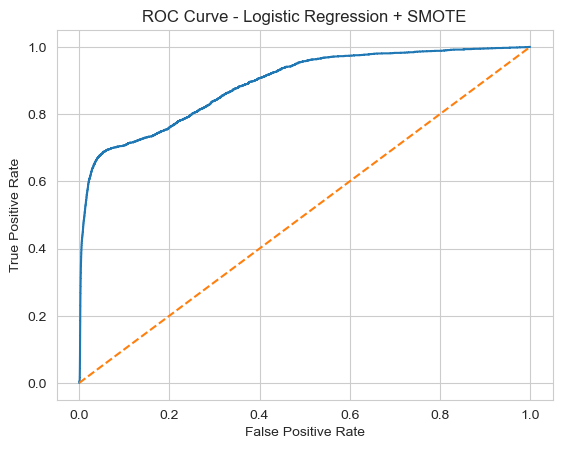

ROC-AUC: 0.8892301383652134


In [116]:
y_prob = lr_smote.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], '--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression + SMOTE")
plt.show()

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

### Interpretation

The ROC-AUC of the Logistic Regression model with SMOTE is **0.889**, which means that if a random fraudulent transaction and a random genuine transaction are compared, the model gives the fraudulent one a higher fraud probability about 89% of the time. The curve lies well above the diagonal, so the model has real ability to separate the two classes. However, ROC-AUC tends to look flattering when genuine transactions vastly outnumber frauds, so the Precision-Recall curve is examined next.

## Precision-Recall Curve: Logistic Regression with SMOTE

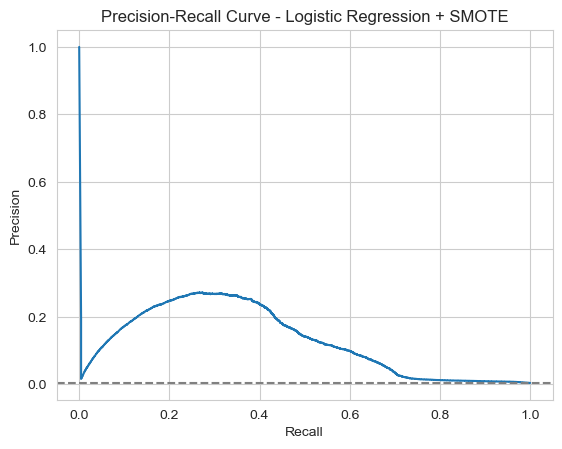

PR-AUC: 0.12577857091164837


In [118]:
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

plt.plot(recall, precision)
plt.axhline(y_test.mean(), linestyle='--', color='grey')
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Logistic Regression + SMOTE")
plt.show()

print("PR-AUC:", average_precision_score(y_test, y_prob))

### Interpretation

The PR-AUC of this model is **0.126**. A model with no skill would score about **0.004** (the fraud rate), so the model is more than 30 times better than guessing. The curve also shows how quickly precision falls as recall increases: catching more fraud means accepting many more false alarms. This is a more realistic picture of the model than the ROC-AUC of 0.889, and it confirms that Logistic Regression is limited for this problem.

## Comparing All Models

The ROC and Precision-Recall curves of all seven models are drawn on the same charts, using the same test set, so that they can be compared directly.

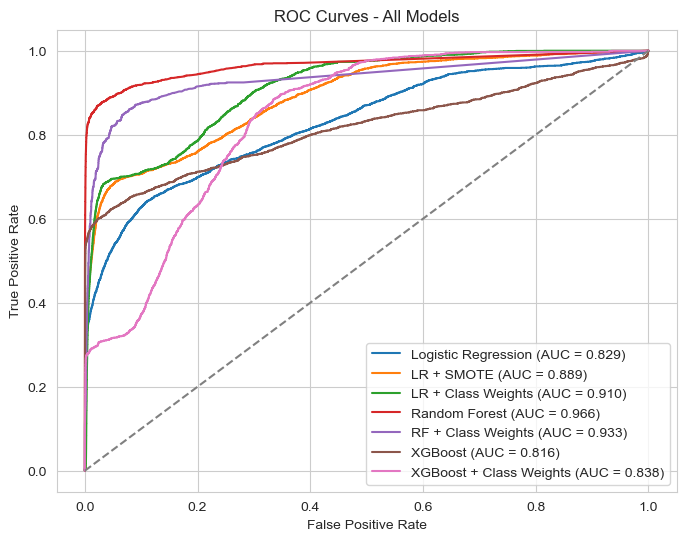

C:\Users\ishik\Downloads\New folder\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


In [ ]:
models = {
    "Logistic Regression": (lr, X_test_scaled),
    "LR + SMOTE": (lr_smote, X_test_scaled),
    "LR + Class Weights": (lr_weighted, X_test_scaled),
    "Random Forest": (rf, X_test),
    "RF + Class Weights": (rf_weighted, X_test),
    "XGBoost": (xgb, X_test),
    "XGBoost + Class Weights": (xgb_weighted, X_test),
}

# ROC curves
plt.figure(figsize=(8, 6))
for name, (model, data) in models.items():
    prob = model.predict_proba(data)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")
plt.plot([0, 1], [0, 1], '--', color='grey')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - All Models")
plt.legend()
plt.show()

# Precision-Recall curves
plt.figure(figsize=(8, 6))
for name, (model, data) in models.items():
    prob = model.predict_proba(data)[:, 1]
    p, r, _ = precision_recall_curve(y_test, prob)
    plt.plot(r, p, label=f"{name} (PR-AUC = {average_precision_score(y_test, prob):.3f})")
plt.axhline(y_test.mean(), linestyle='--', color='grey')
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves - All Models")
plt.legend()
plt.show()

### Interpretation

| Model | ROC-AUC | PR-AUC |
|---|---|---|
| Logistic Regression | 0.829 | 0.134 |
| Logistic Regression + SMOTE | 0.889 | 0.126 |
| Logistic Regression + Class Weights | 0.910 | 0.108 |
| **Random Forest** | **0.966** | **0.721** |
| Random Forest + Class Weights | 0.933 | 0.267 |
| XGBoost | 0.816 | 0.453 |
| XGBoost + Class Weights | 0.838 | 0.197 |

- **The baseline Random Forest is clearly the best model**, with the highest ROC-AUC (0.966) and by far the highest PR-AUC (0.721), about 180 times the no-skill level. Its curve stays high over a wide range of recall, so it can detect many more frauds than the default threshold allows. From the chart, it holds a precision of roughly 80% or more up to a recall of about 60%, compared with a recall of only 38% at the default threshold of 0.50. This suggests that **lowering the Random Forest's threshold could improve fraud detection considerably**.
- **XGBoost is second** on PR-AUC (0.453), but well behind the Random Forest.
- **Class weights hurt the tree-based models.** PR-AUC fell from 0.721 to 0.267 for the Random Forest and from 0.453 to 0.197 for XGBoost, which agrees with the lower F1-scores seen earlier.
- **For Logistic Regression, SMOTE and class weights raised the ROC-AUC (0.829 → 0.889 → 0.910) but not the PR-AUC (0.134 → 0.126 → 0.108).** This indicates that the two techniques mainly shifted the model's probabilities, which helps at a fixed threshold, rather than improving its ability to rank frauds above genuine transactions. It also shows why ROC-AUC alone can be misleading on imbalanced data.
- All models lie above the no-skill baseline, but **all Logistic Regression variants perform far below the tree-based models**, because a linear model cannot capture the complex patterns of fraud.

# 22. Feature Importance and Model Comparison

## Feature Importance

Feature importance shows which variables the models relied on most when learning to separate fraudulent from genuine transactions. The scores come from the models themselves and sum to 1, where a higher value means a greater influence:

- **Random Forest** uses the **reduction in impurity**: every time a feature is used to split the data, the model records how much cleaner the separation of fraud and genuine transactions becomes, and these improvements are added up across all trees.
- **XGBoost** uses **gain**: the average improvement in the model's accuracy brought by the splits that use the feature.

Feature importance describes what the model uses, **not what causes fraud**. It also tends to favour continuous and high-cardinality features, because they offer many possible split points.

### Random Forest: Top 15 Features

In [ ]:
rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf.feature_importances_
})

rf_importance.sort_values(by="Importance", ascending=False).head(15).reset_index(drop=True)

### Interpretation

The Random Forest relies most heavily on the **transaction amount (`amt`), which alone accounts for about 49% of the total importance**. This agrees with the EDA, which showed that fraudulent transactions are much larger than genuine ones. The next most important features are **`city` (10.3%)** and **`age` (8.0%)**, so the top three features together account for about two thirds of the importance.

The 15 features shown account for about 95% of the total importance, so most of the remaining columns contribute very little. The engineered feature `distance_km` ranks low (1.6%), which suggests that the customer's distance from the merchant is not a strong signal in this dataset.

### XGBoost: Top 15 Features

In [ ]:
xgb_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb.feature_importances_
})

xgb_importance.sort_values(by="Importance", ascending=False).head(15).reset_index(drop=True)

### Interpretation

XGBoost shows a very different pattern. Its importance is concentrated in the **merchant category**: **`category_grocery_pos` alone accounts for about 67%**, and with **`gas_transport` (9.5%)** and the **evening period (`hour_group_18-23`, 6.3%)** the top three features make up about 83% of the total. Other relevant features are `category_travel`, `amt`, `gender_M` and `age`.

Unlike the Random Forest, XGBoost gives the transaction amount only about 2.7%, even though the EDA showed it to be a strong indicator. The two methods measure importance differently, and in a boosted model, where each tree corrects the previous ones, a feature used for the first, largest splits can take most of the credit. XGBoost's heavy dependence on a few binary features may also be linked to its lower PR-AUC (0.453) compared with the Random Forest (0.721), although this has not been tested directly.

### What Both Models Agree On

Both models rank **transaction amount, customer age, the `grocery_pos` and `gas_transport` categories, the evening time period and gender** among their most useful features. This matches the main EDA findings: fraud is linked to larger amounts, to particular merchant categories and to the late evening and night hours. Variables such as the customer's distance from the merchant and the state contribute little in either model.

# 23. Conclusion

## Project Summary

This project developed machine learning models to detect fraudulent credit card transactions in a dataset of **1.85 million transactions**, in which only **about 0.5% are fraudulent**. The work covered the full modelling process: data exploration, feature engineering, a chronological train-test split, encoding and scaling without data leakage, the training of three algorithms (**Logistic Regression, Random Forest and XGBoost**), the handling of class imbalance with **SMOTE** and **class weights**, decision threshold analysis, and evaluation using **Precision, Recall, F1-Score, ROC-AUC and PR-AUC**.

## Key Findings

- **Fraud is rare and strongly patterned.** Fraudulent transactions are much larger than genuine ones (median about 390 dollars compared with about 47 dollars), are concentrated in online and grocery point-of-sale categories, and occur mostly in the evening and at night: about **90% of all frauds happen between 18:00 and 05:59**.
- **Accuracy is misleading.** Every model scored above 91% accuracy, and the baseline reached 99.58% while detecting less than 1% of the fraud, so the models were judged mainly on Recall, F1-Score and PR-AUC.
- **The Random Forest was the best model.** It achieved a **precision of 93.6%, a recall of 38.1%, an F1-score of 54.2%, a ROC-AUC of 0.966 and a PR-AUC of 0.721**, clearly ahead of XGBoost (PR-AUC 0.453) and all Logistic Regression variants (PR-AUC about 0.11 to 0.13). Only 56 of the 553,574 genuine test transactions were wrongly flagged.
- **Tree-based models outperform the linear model.** Logistic Regression could not capture the complex patterns of fraud, even with SMOTE or class weights.
- **Class imbalance techniques helped only Logistic Regression**, mainly by shifting its operating point (SMOTE raised its F1-score from 0.014 to 0.294). For the Random Forest and XGBoost, class weights **reduced** performance, and hyperparameter tuning of the Random Forest did not beat the baseline on future data.
- **The decision threshold controls the trade-off** between catching fraud and raising false alarms. Raising the threshold of the class-weighted Logistic Regression lifted its F1-score from 0.063 to 0.256.
- **The most important features** were the transaction amount, merchant category (especially grocery point-of-sale and gas/transport), the evening time period and customer age, which agrees with the findings of the exploratory analysis.

## Business Interpretation

At the default threshold, the Random Forest is very precise: about **94 of every 100 alerts are real fraud**, and fewer than 0.01% of genuine transactions are disturbed. Its weakness is that it detects only about 38% of frauds. The Precision-Recall curve suggests that a lower decision threshold could catch considerably more fraud while keeping precision high, so the final choice would depend on how a business weighs the cost of a missed fraud against the cost of a false alarm.

## Limitations

- The data is a **simulated** dataset, so real-world fraud patterns may differ.
- The fraud rate in the test period (0.39%) is lower than in the training period (0.58%), which makes the test results harder to compare with the training behaviour.
- Thresholds were explored on the test set to illustrate the trade-off. In practice, they should be chosen on a separate validation set.
- Hyperparameter tuning used a small grid and a 200,000-row sample, and only the Random Forest was tuned.
- SMOTE was applied only to the Logistic Regression model, and the Random Forest's decision threshold was not tuned.
- Each transaction was treated independently, without using a customer's transaction history.

## Future Improvements

- Tune the decision threshold of the Random Forest on a **validation set** taken from the end of the training period.
- Create **behavioural features** such as the number of transactions by a card in the last hour or the difference between a transaction and the card's usual spending.
- Try **undersampling** and tune XGBoost more thoroughly, including with time-based cross-validation.
- Use **SHAP values** to explain individual predictions.
- Evaluate the models using the **monetary cost** of missed frauds and false alarms.

### Author - Ishika Agarwal